# Caminho Livre: previsão de risco e de prazos para quem anda a pé

**FIAP · Global Solution 2026.2 (CitizenTech) · Data Science & Statistical Computing**
**Grupo OctoFlow · turma 2ESPV**

| Integrante | RM |
|---|---|
| Caio Nascimento Caminha | 564789 |
| Eduardo Duran Del Ciel | 562017 |
| Eduardo Ulisses Pereira da Silva | 566339 |
| Henrique Castro de Matos | 564560 |
| Laura Tigre Amaral | 565281 |

**Bases de dados (CSV)**

* `ssp_roubos_furtos_capital_2025.csv`: recorte dos microdados de boletins de ocorrência da Secretaria da Segurança Pública de SP (Dados Criminais 2025, [ssp.sp.gov.br/estatistica/consultas](https://www.ssp.sp.gov.br/estatistica/consultas)).
* `sp156_rua_e_bairro_2025.csv`: recorte dos pedidos feitos ao SP156 da Prefeitura de São Paulo (Portal de Dados Abertos, [dados.prefeitura.sp.gov.br/dataset/dados-do-sp156](https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156), licença CC0).

Os recortes (CSV compactado) e os scripts que os geram a partir dos arquivos oficiais ficam no repositório do projeto: [github.com/RickkCastro/caminho-livre](https://github.com/RickkCastro/caminho-livre), na pasta `data-science/dados`. Se a pasta `dados/` não estiver ao lado deste notebook, ele mesmo baixa os arquivos de lá.

### Resumo dos resultados

| Modelo | Resultado no teste (out. a dez. de 2025) | O que recomendamos |
|---|---|---|
| **Regressão linear**: roubos a pedestres por hora | MAE 2,84 · RMSE 3,75 · R² 0,48 (um modelo que só prevê a média fica com R² perto de zero). Com a hora toda escura, há 1,7 roubo a mais por hora, comparando o mesmo horário do relógio | Usar um peso de risco por hora nas rotas, com a "noite" começando no anoitecer de cada dia |
| **Regressão logística**: problema ainda sem solução depois de 15 dias | precisão 0,66 · recall 0,45 · F1 0,53 (limiar 0,45) · AUC 0,72 | Alertas de obstáculo, calçada quebrada e degrau valerem 90 dias, com pedido de confirmação |

## 1. Contexto, perguntas e variáveis-alvo

**O problema.** Quem anda a pé em São Paulo (idosos, cadeirantes, pais com carrinho de bebê, quem volta para casa à noite) quase nunca sabe de antemão onde tem calçada quebrada, obstáculo, buraco, rua alagada ou risco de assalto. O **Caminho Livre** é um mapa colaborativo: a pessoa avisa do problema e o app sugere uma rota que desvia dos alertas.

Hoje o app tem duas regras fixas, e os dados públicos da cidade ajudam a ver se elas fazem sentido:

| Regra no app | Como está hoje | Pergunta para os dados |
|---|---|---|
| Peso de um alerta de **assalto** em cada horário (RF09) | peso maior das 19h às 6h | **P1.** Quantos roubos a pedestres esperar em cada hora do dia? Quanto a escuridão pesa nesse número? |
| Tempo que um alerta sem confirmação fica no mapa (RF14) | 15 dias, para qualquer tipo de problema | **P2.** Qual a probabilidade de um problema na rua continuar sem solução depois de 15 dias? |

**Variáveis-alvo**

| Modelo | Variável-alvo | Tipo | Cada linha é | Base |
|---|---|---|---|---|
| Regressão linear | `roubos`: número de roubos a pedestres em via pública, na cidade de São Paulo, naquela hora | numérica (contagem) | uma hora de um dia, de 01/01 a 15/12/2025 | SSP-SP |
| Regressão logística | `persiste_15d`: **1** se o pedido **não** foi finalizado em até 15 dias, **0** se foi | binária | um pedido ao SP156 em 2025, de um problema que existe como categoria no app | SP156 |

**Variáveis explicativas.** Todas são conhecidas na hora em que a previsão seria feita, para não haver vazamento de dados.

* **Linear:** hora do dia combinada com o tipo de dia (dia útil, sábado, domingo/feriado); fração da hora que está escura (calculada pelo horário do sol); dias desde o começo do ano (tendência).
* **Logística:** serviço pedido (buraco, calçada, obstáculo, rampa, bueiro, escadaria); subprefeitura; dia da semana em que o pedido foi aberto.

A análise não depende do app, os modelos não estão ligados a ele. A seção 7 mostra como as previsões poderiam ser usadas.

## 2. Configuração

Bibliotecas usadas: `pip install pandas numpy scikit-learn matplotlib astral`. O notebook roda em menos de 1 minuto.

In [1]:
import datetime as dt
import urllib.error
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from astral import Observer
from astral.sun import sun
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

DADOS = Path("dados")          # onde ficam as bases
GRAFICOS = Path("graficos")    # onde os gráficos são salvos (PNG)
GRAFICOS.mkdir(exist_ok=True)
REPOSITORIO = ("https://raw.githubusercontent.com/RickkCastro/caminho-livre/main/"
               "data-science/dados")

CORTE_TREINO_TESTE = pd.Timestamp("2025-10-01")  # treino: jan a set | teste: out a dez
FIM_ANALISE = pd.Timestamp("2025-12-15")         # último dia de roubos que entra na análise
DIAS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
MESES = ["jan", "fev", "mar", "abr", "mai", "jun",
         "jul", "ago", "set", "out", "nov", "dez"]

In [2]:
# cores dos gráficos (paleta que funciona para quem tem daltonismo) e estilo do matplotlib
AZUL, LARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_2, TINTA_SUAVE = "#0b0b0b", "#52514e", "#898781"
FUNDO, FAIXA, GRADE, CINZA = "#fcfcfb", "#f0efec", "#e1e0d9", "#c3c2b7"
AZUIS = LinearSegmentedColormap.from_list(
    "azuis", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": CINZA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE, "font.size": 11,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

In [3]:
def ler_base(nome):
    # procura o arquivo na pasta dados/ (.csv ou .csv.gz). Lê tudo como texto e
    # converte os tipos só depois, passo a passo
    for extensao in (".csv", ".csv.gz"):
        caminho = DADOS / f"{nome}{extensao}"
        if caminho.exists():
            return pd.read_csv(caminho, dtype=str, keep_default_na=False)
    # não achou: baixa do repositório do projeto
    DADOS.mkdir(exist_ok=True)
    for extensao in (".csv.gz", ".csv"):
        caminho = DADOS / f"{nome}{extensao}"
        try:
            urllib.request.urlretrieve(f"{REPOSITORIO}/{nome}{extensao}", caminho)
        except urllib.error.HTTPError:
            continue
        print(f"{caminho.name} baixado do repositório do projeto")
        return pd.read_csv(caminho, dtype=str, keep_default_na=False)
    raise FileNotFoundError(f"base {nome} não encontrada")


def salvar(fig, nome):
    # guarda o gráfico em PNG na pasta graficos/
    fig.savefig(GRAFICOS / nome)


def fonte(fig, texto):
    # coloca a fonte dos dados embaixo de tudo que já foi desenhado na figura
    fig.canvas.draw()
    caixa = fig.get_tightbbox(fig.canvas.get_renderer())
    fig.text(caixa.x0 / fig.get_figwidth(), caixa.y0 / fig.get_figheight() - 0.02,
             texto, fontsize=8.5, color=TINTA_SUAVE, va="top")


def pct(x, casas=1):
    # proporção -> porcentagem com vírgula: 0.3506 vira '35,1%'
    return f"{x * 100:.{casas}f}%".replace(".", ",")


def num(x, casas=2):
    # número com vírgula decimal: 2.8412 vira '2,84'
    return f"{x:.{casas}f}".replace(".", ",")

## 3. Dados e fontes

| Base | Fonte | O que tem |
|---|---|---|
| `ssp_roubos_furtos_capital_2025.csv` | **SSP-SP**, *Consultas, Base de Dados, Dados criminais 2025*, arquivo `SPDadosCriminais_2025.xlsx` (versão de 30/06/2026) | 346.702 boletins de ocorrência de roubo e furto ("ROUBO - OUTROS" e "FURTO - OUTROS") na cidade de São Paulo, registrados em 2025 |
| `sp156_rua_e_bairro_2025.csv` | **Prefeitura de São Paulo**, *Dados do SP156, Solicitações*, 4 trimestres de 2025 (publicados em 10/08/2026) | 336.555 pedidos do tema "Rua e bairro" abertos em 2025 |

Os arquivos oficiais somam uns 680 MB. Para o trabalho ficar leve, um script do repositório fez só o recorte acima e a **anonimização**: o número do BO virou um código pseudônimo, logradouro, número e CEP foram descartados e as coordenadas foram arredondadas (cerca de 100 m). Não usamos nenhum dado pessoal. A tabela abaixo mostra quantas linhas sobraram em cada etapa da extração. A limpeza de verdade acontece depois, aqui no notebook.

In [4]:
# quantas linhas sobraram em cada etapa da extração dos arquivos oficiais
ler_base("funil_extracao")

,base,etapa,linhas
0,SSP,"1. linhas no arquivo original (estado de SP, 2...",1161132
1,SSP,2. ocorridas na cidade de São Paulo,468052
2,SSP,3. natureza ROUBO - OUTROS ou FURTO - OUTROS (...,346702
3,SP156,sp156_2025_1tri.csv: linhas no arquivo,1048575
4,SP156,sp156_2025_1tri.csv: linhas totalmente vazias ...,305671
5,SP156,sp156_2025_2tri.csv: linhas no arquivo,589980
6,SP156,sp156_2025_2tri.csv: linhas totalmente vazias ...,0
7,SP156,sp156_2025_3tri.csv: linhas no arquivo,501685
8,SP156,sp156_2025_3tri.csv: linhas totalmente vazias ...,0
9,SP156,sp156_2025_4tri.csv: linhas no arquivo,479701


## 4. Preparação dos dados e separação entre treino e teste

### 4.1 Roubos a pedestres (SSP-SP): base da regressão linear

**Passo 1: nulos.** Na base da SSP, campo vazio vem escrito como o texto `"NULL"` (isso está no dicionário do próprio arquivo). Vamos trocar por nulo de verdade.

In [5]:
ssp_bruto = ler_base("ssp_roubos_furtos_capital_2025")
print(f"{len(ssp_bruto):,} linhas x {ssp_bruto.shape[1]} colunas")

# o texto "NULL" e as células vazias viram nulo (NaN)
ssp = ssp_bruto.replace({"NULL": np.nan, "": np.nan})

# % de nulos, só nas colunas que têm algum
nulos = ssp.isna().mean()
nulos[nulos > 0].map(pct).to_frame("% de nulos")

346,702 linhas x 14 colunas


,% de nulos
HORA_OCORRENCIA_BO,"42,1%"
DESC_PERIODO,"57,9%"
BAIRRO,"0,1%"
LATITUDE,"11,2%"
LONGITUDE,"11,2%"


**Passos 2 a 4: pedestre, duplicatas e tipo de crime.**

* **Pedestre.** O rótulo de conduta "Transeunte" quase não é usado (a maior parte dos roubos de rua aparece como "Outros"). Então definimos roubo ou furto a pedestre como o que aconteceu em **via pública**, com conduta **"Transeunte" ou "Outros"** e **fora** de veículos e de transporte coletivo.
* **Duplicatas.** Um mesmo BO pode aparecer duas vezes (uma como furto e outra como roubo). Deixamos uma linha por BO e, na dúvida, ficamos com o roubo.
* **Só roubos.** A variável-alvo conta **roubos**, isto é, crime com violência ou ameaça, que é o "assalto" do app. Os furtos ficam de fora: quase metade deles não tem hora exata (a vítima só percebe depois) e não representam o risco do alerta de assalto.

In [6]:
etapas = [("extrato: capital, roubo/furto 'outros'", len(ssp))]

# passo 2: pedestre = via pública, conduta "Transeunte" ou "Outros",
# e que não foi dentro de veículo ou transporte coletivo
DENTRO_DE_VEICULO = ["Interior de Transporte Coletivo", "Veículo em movimento",
                     "Interior de Veículo Particular", "Interior de Veículo de Carga"]
ssp = ssp[(ssp["DESCR_TIPOLOCAL"] == "Via Pública")
          & ssp["DESCR_CONDUTA"].isin(["Transeunte", "Outros"])
          & ~ssp["DESCR_SUBTIPOLOCAL"].isin(DENTRO_DE_VEICULO)]
etapas.append(("2. roubo ou furto a pedestre em via pública", len(ssp)))

# passo 3: um BO por linha. Na ordem decrescente "ROUBO" vem antes de "FURTO",
# então quando o BO está duplicado sobra a linha do roubo
print("linhas de BOs repetidos:", ssp["ID_BO_PSEUDONIMO"].duplicated(keep=False).sum())
ssp = (ssp.sort_values("NATUREZA_APURADA", ascending=False)
          .drop_duplicates("ID_BO_PSEUDONIMO"))
etapas.append(("3. uma linha por boletim", len(ssp)))

# passo 4: só roubos. Antes disso, vê quanto de cada tipo está sem hora exata
sem_hora_tipo = (ssp.groupby("NATUREZA_APURADA")["HORA_OCORRENCIA_BO"]
                    .apply(lambda s: s.isna().mean()))
print("sem hora exata:", sem_hora_tipo.map(pct).to_dict())
ssp = ssp[ssp["NATUREZA_APURADA"] == "ROUBO - OUTROS"].copy()
etapas.append(("4. só roubos (o alerta de assalto do app)", len(ssp)))

linhas de BOs repetidos: 56


sem hora exata: {'FURTO - OUTROS': '48,1%', 'ROUBO - OUTROS': '9,8%'}


**Passo 5: datas e atraso de registro.** O arquivo tem os BOs **registrados** em 2025, o que traz dois cuidados:

* alguns BOs registrados em 2025 falam de fatos de anos anteriores, então ficamos só com os fatos de 2025;
* o contrário também acontece: fatos do fim de dezembro de 2025 que só foram registrados em janeiro de 2026 **não estão** no arquivo. Por isso, no gráfico abaixo, a queda brusca do fim de dezembro é falta de registro e não queda real de roubos. A análise vai **até 15/12/2025**.

O gráfico também deixa ver uma **tendência de queda** ao longo do ano, que entra no modelo como variável.

In [7]:
# datas do fato e do registro (a hora do dia fica de fora por enquanto)
ssp["data"] = pd.to_datetime(ssp["DATA_OCORRENCIA_BO"], errors="coerce").dt.normalize()
ssp["registro"] = pd.to_datetime(ssp["DATA_REGISTRO"], errors="coerce").dt.normalize()
print("ano do fato:", ssp["data"].dt.year.value_counts().head(4).to_dict())
ssp = ssp[ssp["data"].dt.year == 2025]          # só fatos que aconteceram em 2025

# quantos dias passaram entre o fato e o registro do BO
atraso = (ssp["registro"] - ssp["data"]).dt.days
print(f"registrados mais de 7 dias depois do fato: {pct((atraso > 7).mean())}")
print(f"registrados mais de 15 dias depois do fato: {pct((atraso > 15).mean())}")

# roubos por dia no ano todo (dia sem roubo conta como zero), para o gráfico
por_dia = (ssp.groupby("data").size()
              .reindex(pd.date_range("2025-01-01", "2025-12-31"), fill_value=0))

ano do fato: {2025: 84048, 2024: 976, 2015: 55, 2023: 39}
registrados mais de 7 dias depois do fato: 5,5%
registrados mais de 15 dias depois do fato: 2,4%


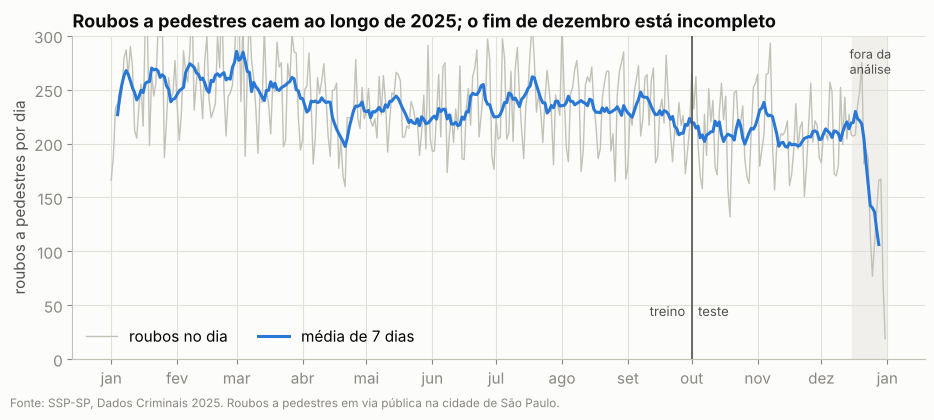

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axvspan(FIM_ANALISE + pd.Timedelta(hours=12), pd.Timestamp("2025-12-31 12:00"),
           color=FAIXA, zorder=0)                       # trecho que fica de fora
ax.plot(por_dia.index, por_dia, color=CINZA, linewidth=1, label="roubos no dia")
ax.plot(por_dia.index, por_dia.rolling(7, center=True).mean(), color=AZUL,
        linewidth=2.2, label="média de 7 dias")
ax.axvline(CORTE_TREINO_TESTE, color=TINTA_2, linewidth=1.2)  # linha treino/teste
ax.text(CORTE_TREINO_TESTE - pd.Timedelta(days=3), 40, "treino", ha="right",
        color=TINTA_2, fontsize=9.5)
ax.text(CORTE_TREINO_TESTE + pd.Timedelta(days=3), 40, "teste", ha="left",
        color=TINTA_2, fontsize=9.5)
ax.text(pd.Timestamp("2025-12-24"), 290, "fora da\nanálise", ha="center", va="top",
        color=TINTA_2, fontsize=9)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda v, _: MESES[mdates.num2date(v).month - 1]))
ax.set_ylim(0, 300)
ax.set_ylabel("roubos a pedestres por dia")
ax.set_title("Roubos a pedestres caem ao longo de 2025; "
             "o fim de dezembro está incompleto")
ax.legend(loc="lower left", ncols=2)
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025. Roubos a pedestres em via pública "
           "na cidade de São Paulo.")
salvar(fig, "01_roubos_por_dia_2025.png")
plt.show()

In [9]:
# fatos registrados só depois de 2025 não estão no arquivo, então cortamos em 15/12/2025
ssp = ssp[ssp["data"] <= FIM_ANALISE]
etapas.append(("5. fato entre 01/01 e 15/12/2025", len(ssp)))

**Passo 6: hora.** Passamos a hora para número (0 a 23). Os roubos sem hora exata ficam fora da contagem por hora. Como a vítima costuma *estimar* o horário (tem muito horário "redondo"), trabalhamos com a hora cheia e não com o minuto.

In [10]:
hora = pd.to_datetime(ssp["HORA_OCORRENCIA_BO"], format="%H:%M:%S", errors="coerce")
sem_hora = hora.isna()
print(f"roubos sem hora exata: {sem_hora.sum():,} ({pct(sem_hora.mean())}),"
      " ficam fora da contagem por hora")

# muitos horários terminam em :00, sinal de que a vítima chutou a hora
redondos = (hora[~sem_hora].dt.minute == 0).mean()
print(f"horários terminados em :00: {pct(redondos)} (se fosse ao acaso: {pct(1 / 60)})")

roubos_com_hora = ssp[~sem_hora].copy()
roubos_com_hora["hora"] = hora[~sem_hora].dt.hour.astype(int)   # hora cheia, de 0 a 23
etapas.append(("6. com hora exata (entram na variável-alvo)", len(roubos_com_hora)))
pd.DataFrame(etapas, columns=["etapa do preparo", "registros"])

roubos sem hora exata: 7,960 (9,8%), ficam fora da contagem por hora
horários terminados em :00: 26,2% (se fosse ao acaso: 1,7%)


,etapa do preparo,registros
0,"extrato: capital, roubo/furto 'outros'",346702
1,2. roubo ou furto a pedestre em via pública,254472
2,3. uma linha por boletim,254444
3,4. só roubos (o alerta de assalto do app),85185
4,5. fato entre 01/01 e 15/12/2025,81455
5,6. com hora exata (entram na variável-alvo),73495


**Passo 7: tabela do modelo, uma linha por hora.** Contamos os roubos de cada hora de cada dia (hora sem roubo entra com zero) e criamos as variáveis explicativas:

* `tipo_dia`: dia útil, sábado ou domingo/feriado (usamos o calendário de feriados de 2025 de São Paulo);
* `hora_tipo`: a hora junto com o tipo de dia, porque a madrugada de sábado não é igual à de terça-feira;
* `escuro`: fração da hora que está escura, de 0 (toda clara) a 1 (toda escura). Usamos o **amanhecer** e o **anoitecer** de cada dia (começo e fim do crepúsculo civil), calculados com a biblioteca `astral` para a latitude e a longitude de São Paulo. Assim, as 18h contam como escuras em junho e como claras em dezembro;
* `dias_desde_inicio`: dias passados desde 1º de janeiro, para pegar a tendência de queda.

In [11]:
# uma linha para cada hora de cada dia (349 dias x 24 horas)
dias = pd.date_range("2025-01-01", FIM_ANALISE)
grade = pd.MultiIndex.from_product([dias, range(24)], names=["data", "hora"])

# conta os roubos de cada (data, hora); hora sem roubo fica com zero
base_linear = (roubos_com_hora.groupby(["data", "hora"]).size()
               .reindex(grade, fill_value=0)
               .rename("roubos")
               .reset_index())

# horário do sol em São Paulo em cada dia (dawn = amanhecer, dusk = anoitecer)
SAO_PAULO = Observer(latitude=-23.55, longitude=-46.63)
FUSO = dt.timezone(dt.timedelta(hours=-3))    # SP não tem mais horário de verão


def em_horas(momento):
    # horário em horas decimais: 18:30 vira 18.5
    return momento.hour + momento.minute / 60


sol = pd.DataFrame([
    {"data": dia,
     "amanhecer": em_horas(sun(SAO_PAULO, date=dia.date(), tzinfo=FUSO)["dawn"]),
     "anoitecer": em_horas(sun(SAO_PAULO, date=dia.date(), tzinfo=FUSO)["dusk"])}
    for dia in dias
]).set_index("data")
base_linear = base_linear.join(sol, on="data")
print(f"{len(base_linear):,} horas | média de "
      f"{num(base_linear['roubos'].mean(), 1)} roubos por hora")

8,376 horas | média de 8,8 roubos por hora


In [12]:
FERIADOS_2025 = pd.to_datetime([
    "2025-01-01", "2025-01-25",    # Confraternização Universal, aniversário de SP
    "2025-03-03", "2025-03-04",    # Carnaval
    "2025-04-18", "2025-04-21",    # Sexta-feira Santa, Tiradentes
    "2025-05-01", "2025-06-19",    # Dia do Trabalho, Corpus Christi
    "2025-07-09",                  # Revolução Constitucionalista (feriado estadual)
    "2025-09-07", "2025-10-12",    # Independência, Nossa Senhora Aparecida
    "2025-11-02", "2025-11-15",    # Finados, Proclamação da República
    "2025-11-20", "2025-12-25",    # Consciência Negra, Natal
])

# escuro = parte da hora antes do amanhecer + parte depois do anoitecer (vai de 0 a 1)
h = base_linear["hora"]
antes_do_amanhecer = np.clip(base_linear["amanhecer"] - h, 0, 1)
depois_do_anoitecer = np.clip(h + 1 - base_linear["anoitecer"], 0, 1)
base_linear["escuro"] = (antes_do_amanhecer + depois_do_anoitecer).clip(0, 1)

# tipo_dia: domingo e feriado juntos, depois sábado e dia útil
dia_semana = base_linear["data"].dt.dayofweek               # 0 = segunda, 6 = domingo
domingo_ou_feriado = base_linear["data"].isin(FERIADOS_2025) | (dia_semana == 6)
base_linear["tipo_dia"] = np.select([domingo_ou_feriado, dia_semana == 5],
                                    ["domingo/feriado", "sábado"], default="dia útil")

# hora_tipo = hora + tipo de dia, por exemplo "20h · dia útil"
base_linear["hora_tipo"] = (base_linear["hora"].map("{:02d}h".format)
                            + " · " + base_linear["tipo_dia"])

# dias_desde_inicio: a tendência ao longo do ano
base_linear["dias_desde_inicio"] = (base_linear["data"]
                                    - pd.Timestamp("2025-01-01")).dt.days

colunas = ["data", "hora", "tipo_dia", "hora_tipo", "escuro", "dias_desde_inicio",
           "roubos"]
base_linear[colunas].sample(5, random_state=1)

,data,hora,tipo_dia,hora_tipo,escuro,dias_desde_inicio,roubos
2065,2025-03-28,1,dia útil,01h · dia útil,1.00,86,7
1117,2025-02-16,13,domingo/feriado,13h · domingo/feriado,0.00,46,5
7492,2025-11-09,4,domingo/feriado,04h · domingo/feriado,0.85,312,12
946,2025-02-09,10,domingo/feriado,10h · domingo/feriado,0.00,39,6
3532,2025-05-28,4,dia útil,04h · dia útil,1.00,147,12


**Exploração (só com os dados de treino, de janeiro a setembro).** O padrão por hora muda conforme o tipo de dia, e por isso faz sentido juntar hora e tipo de dia numa variável só. Para não "espiar" o teste, essa exploração usa apenas o período de treino.

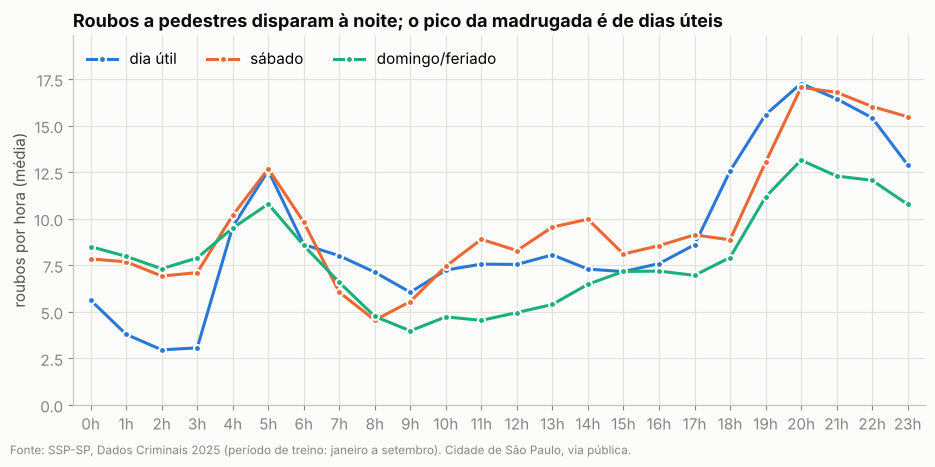

In [13]:
# média de roubos por hora em cada tipo de dia, só no treino
explorar = base_linear[base_linear["data"] < CORTE_TREINO_TESTE]
perfil = explorar.pivot_table(index="hora", columns="tipo_dia", values="roubos",
                              aggfunc="mean")

fig, ax = plt.subplots(figsize=(11, 4.8))
for tipo, cor in [("dia útil", AZUL), ("sábado", LARANJA),
                  ("domingo/feriado", VERDE_AGUA)]:
    ax.plot(perfil.index, perfil[tipo], color=cor, linewidth=2.2, marker="o",
            markersize=5, markeredgecolor=FUNDO, markeredgewidth=1.5, label=tipo)
ax.set_xticks(range(24), [f"{h}h" for h in range(24)])
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, perfil.to_numpy().max() * 1.15)
ax.set_ylabel("roubos por hora (média)")
ax.set_title("Roubos a pedestres disparam à noite; o pico da madrugada é de dias úteis")
ax.legend(loc="upper left", ncols=3)
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025 (período de treino: janeiro a "
           "setembro). Cidade de São Paulo, via pública.")
salvar(fig, "02_roubos_por_hora_e_tipo_de_dia.png")
plt.show()

### 4.2 Pedidos ao SP156: base da regressão logística

**Passo 1: nulos, datas e subprefeitura.** As datas vêm no formato brasileiro. A coluna de subprefeitura tem grafias alternativas ("CASA VERDE-LIMAO-CACHOEIRINHA", "PERUS-ANHANGUERA") e também valores que nem são subprefeitura (órgãos da Prefeitura, "Prefeitura Regional nao encontrada"). Padronizamos as grafias e deixamos o resto como nulo.

In [14]:
sp156_bruto = ler_base("sp156_rua_e_bairro_2025")
print(f"{len(sp156_bruto):,} linhas x {sp156_bruto.shape[1]} colunas")
sp156 = sp156_bruto.replace({"": np.nan})          # célula vazia vira nulo

# datas no formato brasileiro (dia/mês/ano)
sp156["abertura"] = pd.to_datetime(sp156["Data de Abertura"], format="%d/%m/%Y",
                                   errors="coerce")
sp156["finalizacao"] = pd.to_datetime(sp156["Data de Finalização"], format="%d/%m/%Y",
                                      errors="coerce")
print("data de abertura inválida:", sp156["abertura"].isna().sum())

# as 32 subprefeituras da cidade
SUBPREFEITURAS = [
    "ARICANDUVA-FORMOSA-CARRAO", "BUTANTA", "CAMPO LIMPO", "CAPELA DO SOCORRO",
    "CASA VERDE-CACHOEIRINHA", "CIDADE ADEMAR", "CIDADE TIRADENTES",
    "ERMELINO MATARAZZO", "FREGUESIA-BRASILANDIA", "GUAIANASES", "IPIRANGA",
    "ITAIM PAULISTA", "ITAQUERA", "JABAQUARA", "JACANA-TREMEMBE", "LAPA",
    "M BOI MIRIM", "MOOCA", "PARELHEIROS", "PENHA", "PERUS", "PINHEIROS",
    "PIRITUBA-JARAGUA", "SANTANA-TUCURUVI", "SANTO AMARO", "SAO MATEUS",
    "SAO MIGUEL", "SAPOPEMBA", "SE", "VILA MARIA-VILA GUILHERME", "VILA MARIANA",
    "VILA PRUDENTE",
]
# junta as grafias alternativas; o que não for subprefeitura vira nulo
sp156["subprefeitura"] = sp156["Prefeitura Operacional"].replace({
    "CASA VERDE-LIMAO-CACHOEIRINHA": "CASA VERDE-CACHOEIRINHA",
    "PERUS-ANHANGUERA": "PERUS"})
invalidas = ~sp156["subprefeitura"].isin(SUBPREFEITURAS)
print("valores que não são subprefeitura:")
print(sp156.loc[invalidas, "subprefeitura"].value_counts(dropna=False).to_string())
sp156.loc[invalidas, "subprefeitura"] = np.nan

336,555 linhas x 10 colunas
data de abertura inválida: 0


valores que não são subprefeitura:
subprefeitura
Superintendencia das Usinas de Asfalto              1234
NaN                                                  435
Prefeitura Regional nao encontrada                   274
Departamento de Aguas e Energia Eletrica              11
Secretaria Municipal do Verde e do Meio Ambiente       3
Departamento de Estradas de Rodagem                    2


**Passo 2: do SP156 para as categorias do app.** Mantivemos só os serviços que têm categoria de alerta correspondente no Caminho Livre. A categoria "rua escura" não entrou porque o SP156 de 2025 não tem nenhum serviço de iluminação pública.

| Categoria no app | Serviços do SP156 |
|---|---|
| Buraco | tapa-buraco; tapa-buraco em corredor de ônibus |
| Calçada quebrada | manutenção de calçada pública; calçada particular danificada ou inexistente |
| Obstáculo na calçada | avaliação de obstáculo na calçada (acessibilidade) |
| Falta de rampa | rebaixamento de guia para travessia de pedestres |
| Alagamento | limpeza de bueiro; bueiro e boca de lobo; reforma de galeria pluvial; microdrenagem |
| Degrau (escadaria ou viela) | manutenção de vielas e escadarias |

**Passo 3: variável-alvo.** `persiste_15d = 1` quando o pedido **não** foi finalizado em até 15 dias (ainda estava aberto, em andamento ou foi finalizado depois disso). Como os dados foram gerados em agosto de 2026, todo pedido de 2025 teve bem mais de 15 dias de acompanhamento, então a resposta é conhecida para todos. Os pedidos **cancelados pelo próprio cidadão** saem, porque não dizem se o problema foi resolvido.

In [15]:
# nome do serviço no SP156: (nome curto, categoria de alerta no app)
SERVICOS = {
    "Tapa-buraco": ("Tapa-buraco", "Buraco"),
    "Tapa-buraco em faixa exclusiva ou corredor de ônibus":
        ("Tapa-buraco em corredor de ônibus", "Buraco"),
    "Calçada pública - solicitar manutenção":
        ("Calçada pública: manutenção", "Calçada quebrada"),
    "Calçada particular - denunciar calçada danificada ou inexistente":
        ("Calçada particular danificada", "Calçada quebrada"),
    "Acessibilidade - solicitar avaliação de obstáculo na calçada":
        ("Obstáculo na calçada", "Obstáculo na calçada"),
    "Guias para travessia de pedestres - Solicitar rebaixamento":
        ("Rebaixamento de guia", "Falta de rampa"),
    "Solicitar limpeza de bueiros, boca de lobo e poços de visita":
        ("Limpeza de bueiro", "Alagamento"),
    "Drenagem de água da chuva - Bueiros e bocas de lobo":
        ("Bueiro e boca de lobo", "Alagamento"),
    "Reformar galerias de águas de chuvas (pluviais)":
        ("Reforma de galeria pluvial", "Alagamento"),
    "Microdrenagem": ("Microdrenagem", "Alagamento"),
    "Vielas e escadarias - solicitar manutenção":
        ("Viela ou escadaria", "Degrau (escadaria ou viela)"),
}

In [16]:
etapas156 = [("extrato: tema 'Rua e bairro' em 2025", len(sp156))]

# só os serviços que existem como categoria de alerta no app
pedidos = sp156[sp156["Serviço"].isin(list(SERVICOS))]
etapas156.append(("1. serviços que existem como categoria no app", len(pedidos)))
print("status:", pedidos["Status"].value_counts().to_dict())

# cancelado pelo cidadão não diz se o problema foi resolvido, então sai
pedidos = pedidos[pedidos["Status"] != "Cancelada"]
etapas156.append(("2. sem pedidos cancelados pelo cidadão", len(pedidos)))
pedidos = pedidos.dropna(subset=["subprefeitura"])
etapas156.append(("3. com subprefeitura válida", len(pedidos)))

# "Finalizada" sem data de finalização: não dá para calcular o prazo, então sai
sem_data = (pedidos["Status"] == "Finalizada") & pedidos["finalizacao"].isna()
print("finalizados sem data de finalização (saem):", sem_data.sum())
pedidos = pedidos[~sem_data].copy()
etapas156.append(("4. sem 'Finalizada' sem data de finalização", len(pedidos)))

# variável-alvo: 1 = não foi finalizado em até 15 dias
dias_ate_finalizar = (pedidos["finalizacao"] - pedidos["abertura"]).dt.days
print("datas inconsistentes (fim antes do início):", (dias_ate_finalizar < 0).sum())
resolvido_15 = (pedidos["Status"] == "Finalizada") & (dias_ate_finalizar <= 15)
pedidos["persiste_15d"] = (~resolvido_15).astype(int)

# variáveis explicativas: serviço (nome curto), categoria do app e dia da semana
pedidos["servico"] = pedidos["Serviço"].map(lambda s: SERVICOS[s][0])
pedidos["categoria_app"] = pedidos["Serviço"].map(lambda s: SERVICOS[s][1])
pedidos["dia_semana"] = pedidos["abertura"].dt.dayofweek.map(dict(enumerate(DIAS)))

print(f"base da regressão logística: {len(pedidos):,} pedidos | "
      f"persiste_15d = 1 em {pct(pedidos['persiste_15d'].mean())}")
pd.DataFrame(etapas156, columns=["etapa do preparo", "pedidos"])

status: {'Finalizada': 162138, 'Aberto': 12658, 'Cancelada': 884, 'Em Andamento': 69}
finalizados sem data de finalização (saem): 19
datas inconsistentes (fim antes do início): 0


base da regressão logística: 173,783 pedidos | persiste_15d = 1 em 31,6%


,etapa do preparo,pedidos
0,extrato: tema 'Rua e bairro' em 2025,336555
1,1. serviços que existem como categoria no app,175749
2,2. sem pedidos cancelados pelo cidadão,174865
3,3. com subprefeitura válida,173802
4,4. sem 'Finalizada' sem data de finalização,173783


**Exploração (só com os dados de treino).** A chance de o problema continuar depois de 15 dias muda muito de uma categoria para outra, então o serviço pedido deve ser a variável mais importante do modelo.

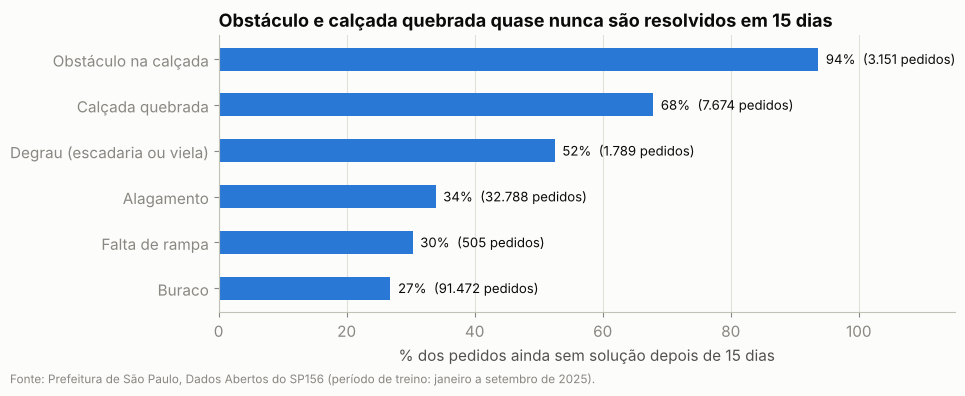

In [17]:
# proporção de pedidos que persistem em cada categoria, só no treino
explorar = pedidos[pedidos["abertura"] < CORTE_TREINO_TESTE]
taxa = (explorar.groupby("categoria_app")["persiste_15d"]
                .agg(["mean", "size"]).sort_values("mean"))

fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.barh(taxa.index, taxa["mean"] * 100, color=AZUL, height=0.5)
for i, (valor, n) in enumerate(zip(taxa["mean"], taxa["size"])):
    rotulo = f"{pct(valor, 0)}  ({n:,} pedidos)".replace(",", ".")
    ax.text(valor * 100 + 1.2, i, rotulo, va="center", color=TINTA, fontsize=9.5)
ax.set_xlim(0, 115)
ax.set_xticks(range(0, 101, 20))
ax.grid(axis="y", visible=False)
ax.set_xlabel("% dos pedidos ainda sem solução depois de 15 dias")
ax.set_title("Obstáculo e calçada quebrada quase nunca são resolvidos em 15 dias")
fonte(fig, "Fonte: Prefeitura de São Paulo, Dados Abertos do SP156 (período de "
           "treino: janeiro a setembro de 2025).")
salvar(fig, "03_persistencia_por_categoria.png")
plt.show()

### 4.3 Separação entre treino e teste, sem vazamento de dados

**Como dividimos.** Nos dois modelos a divisão é pela **data**: o modelo aprende com **janeiro a setembro de 2025** (treino) e é avaliado em **outubro a dezembro de 2025** (teste), como se estivesse prevendo o futuro. Uma divisão aleatória misturaria dias vizinhos, e semanas muito parecidas, entre treino e teste, e o resultado pareceria melhor do que realmente é.

**Cuidados contra vazamento de dados:**

1. **Nada do futuro.** Todo o teste vem depois de todo o treino (conferido no código abaixo).
2. **Nada que dependa da resposta.** `Status`, `Data de Finalização` e o tempo até finalizar **não** entram como variáveis, porque só se sabe isso depois. Vale o mesmo para o órgão responsável, que pode mudar durante o atendimento (ele nem está no recorte).
3. **Preparo aprendido só no treino.** A transformação das categorias em colunas 0/1 (*one-hot*) fica dentro de um `Pipeline` do scikit-learn, que ajusta isso apenas com o treino.
4. **Limiar da logística escolhido sem olhar o teste.** Usamos uma validação dentro do próprio treino (seção 6).
5. **Só variáveis conhecidas na hora da previsão:** hora, tipo de dia, horário do sol (calculado por astronomia), data, serviço pedido, subprefeitura e dia da semana.
6. **Exploração só no treino.** Os gráficos que nos ajudaram a escolher as variáveis usaram apenas janeiro a setembro.

In [18]:
# variáveis explicativas de cada modelo
X_LINEAR = ["hora_tipo", "escuro", "dias_desde_inicio"]
X_LOGISTICA = ["servico", "subprefeitura", "dia_semana"]

# divisão pelo tempo: treino até 30/09/2025, teste de 01/10/2025 em diante
treino_lin = base_linear[base_linear["data"] < CORTE_TREINO_TESTE]
teste_lin = base_linear[base_linear["data"] >= CORTE_TREINO_TESTE]
treino_log = pedidos[pedidos["abertura"] < CORTE_TREINO_TESTE]
teste_log = pedidos[pedidos["abertura"] >= CORTE_TREINO_TESTE]

# conferências: se alguma regra for quebrada o notebook para com erro
assert treino_lin["data"].max() < teste_lin["data"].min()
assert treino_log["abertura"].max() < teste_log["abertura"].min()
proibidas = {"Status", "Data de Finalização", "finalizacao", "persiste_15d"}
assert not proibidas & set(X_LOGISTICA)
assert "roubos" not in X_LINEAR
print("OK: todo o teste é posterior ao treino e nenhuma variável usa a resposta.")


def resumo(modelo, conjunto, datas, alvo):
    # uma linha da tabela: período, tamanho e média da variável-alvo
    return {"modelo": modelo, "conjunto": conjunto,
            "de": datas.min().strftime("%d/%m/%Y"),
            "até": datas.max().strftime("%d/%m/%Y"),
            "linhas": len(alvo), "média do alvo": round(alvo.mean(), 3)}


pd.DataFrame([
    resumo("linear", "treino", treino_lin["data"], treino_lin["roubos"]),
    resumo("linear", "teste", teste_lin["data"], teste_lin["roubos"]),
    resumo("logística", "treino", treino_log["abertura"], treino_log["persiste_15d"]),
    resumo("logística", "teste", teste_log["abertura"], teste_log["persiste_15d"]),
]).set_index(["modelo", "conjunto"])

OK: todo o teste é posterior ao treino e nenhuma variável usa a resposta.


de         até  linhas  média do alvo
modelo    conjunto                                               
linear    treino    01/01/2025  30/09/2025    6552          9.002
          teste     01/10/2025  15/12/2025    1824          7.956
logística treino    01/01/2025  30/09/2025  137379          0.327
          teste     01/10/2025  31/12/2025   36404          0.273

## 5. Regressão linear: quantos roubos a pedestres em cada hora?

**Modelo:** `roubos = b0 + b(hora_tipo) + b1·escuro + b2·dias_desde_inicio + erro`

* `hora_tipo` vira 72 colunas 0/1 (24 horas x 3 tipos de dia). Uma delas fica de fora (`drop="first"`) para servir de referência, assim os coeficientes não ficam redundantes com o intercepto.
* `escuro` e `dias_desde_inicio` entram como números mesmo.

**Referência para comparar:** prever sempre a **média do treino**, ou seja, um "modelo" que não sabe nada. Se a regressão não for bem melhor que isso, ela não serve para nada.

**Métricas no teste:**

* **MAE** (erro absoluto médio): quantos roubos por hora o modelo erra, em média;
* **RMSE** (raiz do erro quadrático médio): parecido com o MAE, só que pesa mais os erros grandes;
* **R²**: que parte da variação de uma hora para outra o modelo consegue explicar (0 = nada, 1 = tudo).

In [19]:
# Pipeline: transforma hora_tipo em colunas 0/1, deixa as variáveis numéricas
# como estão ("passthrough") e depois ajusta a regressão linear
modelo_linear = Pipeline([
    ("preparo", ColumnTransformer(
        [("categorias", OneHotEncoder(drop="first"), ["hora_tipo"])],
        remainder="passthrough")),
    ("regressao", LinearRegression()),
])
modelo_linear.fit(treino_lin[X_LINEAR], treino_lin["roubos"])   # aprende só no treino
previsto_treino = modelo_linear.predict(treino_lin[X_LINEAR])
previsto_teste = modelo_linear.predict(teste_lin[X_LINEAR])


def metricas_regressao(real, previsto):
    return {"MAE": mean_absolute_error(real, previsto),
            "RMSE": np.sqrt(mean_squared_error(real, previsto)),
            "R²": r2_score(real, previsto)}


# referência: prever sempre a média do treino
media_treino = np.full(len(teste_lin), treino_lin["roubos"].mean())
metricas_lin = pd.DataFrame({
    "referência: média do treino (teste)":
        metricas_regressao(teste_lin["roubos"], media_treino),
    "regressão linear (treino)":
        metricas_regressao(treino_lin["roubos"], previsto_treino),
    "regressão linear (teste)":
        metricas_regressao(teste_lin["roubos"], previsto_teste),
}).T
print("previsões negativas no teste:", (previsto_teste < 0).sum())
metricas_lin.round(3)

previsões negativas no teste: 0


,MAE,RMSE,R²
referência: média do treino (teste),4.200,5.314,-0.040
regressão linear (treino),2.896,3.845,0.494
regressão linear (teste),2.844,3.745,0.483


In [20]:
# coeficientes do modelo, com o nome de cada coluna depois do one-hot
nomes = modelo_linear.named_steps["preparo"].get_feature_names_out()
coef = pd.Series(modelo_linear.named_steps["regressao"].coef_, index=nomes)
b_escuro = coef["remainder__escuro"]
b_tendencia = coef["remainder__dias_desde_inicio"]
media_18h = treino_lin.loc[treino_lin["hora"] == 18, "roubos"].mean()

# contagens pequenas variam por acaso em volta da média (ruído de Poisson, em que
# a variância é igual à média). Tirando esse acaso, o R² máximo possível fica perto de:
teto_r2 = 1 - teste_lin["roubos"].mean() / teste_lin["roubos"].var()

print(f"escuro: {num(b_escuro)} roubo por hora quando a hora está toda escura")
print(f"        (às 18h a média é {num(media_18h, 1)} roubos/hora: "
      f"o escuro soma {pct(b_escuro / media_18h, 0)})")
print(f"dias_desde_inicio: {num(b_tendencia, 4)} por dia = "
      f"{num(b_tendencia * 30)} roubo/hora a cada 30 dias")
print(f"R² máximo possível (descontado o acaso das contagens): cerca de {num(teto_r2)}")

escuro: 1,72 roubo por hora quando a hora está toda escura
        (às 18h a média é 11,2 roubos/hora: o escuro soma 15%)
dias_desde_inicio: -0,0049 por dia = -0,15 roubo/hora a cada 30 dias
R² máximo possível (descontado o acaso das contagens): cerca de 0,71


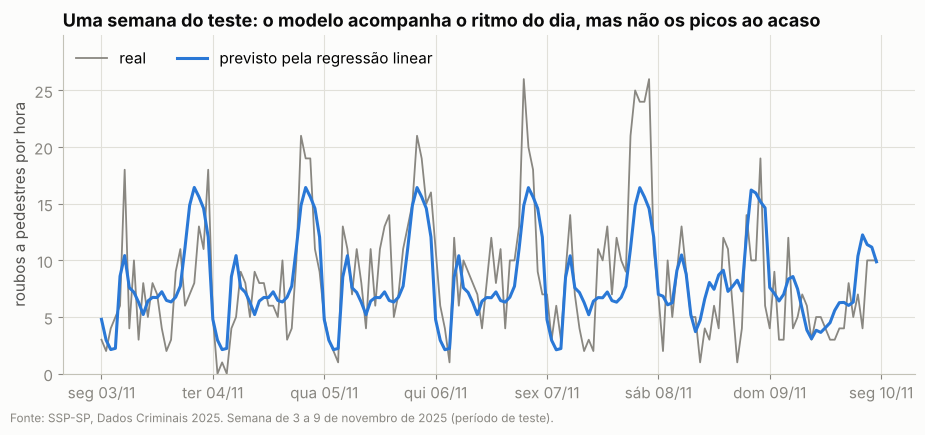

In [21]:
# uma semana do teste: valores reais e previstos, hora a hora
semana = teste_lin[(teste_lin["data"] >= "2025-11-03")
                   & (teste_lin["data"] <= "2025-11-09")]
instantes = semana["data"] + pd.to_timedelta(semana["hora"], unit="h")
previsto_semana = modelo_linear.predict(semana[X_LINEAR])

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(instantes, semana["roubos"], color=TINTA_SUAVE, linewidth=1.3, label="real")
ax.plot(instantes, previsto_semana, color=AZUL, linewidth=2.2,
        label="previsto pela regressão linear")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(FuncFormatter(
    lambda v, _: f"{DIAS[mdates.num2date(v).weekday()]} "
                 f"{mdates.num2date(v).day:02d}/11"))
ax.set_ylabel("roubos a pedestres por hora")
ax.set_ylim(0, max(semana["roubos"].max(), previsto_semana.max()) * 1.15)
ax.set_title("Uma semana do teste: o modelo acompanha o ritmo do dia, "
             "mas não os picos ao acaso")
ax.legend(loc="upper left", ncols=2)
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025. Semana de 3 a 9 de novembro de 2025 "
           "(período de teste).")
salvar(fig, "04_linear_semana_real_vs_previsto.png")
plt.show()

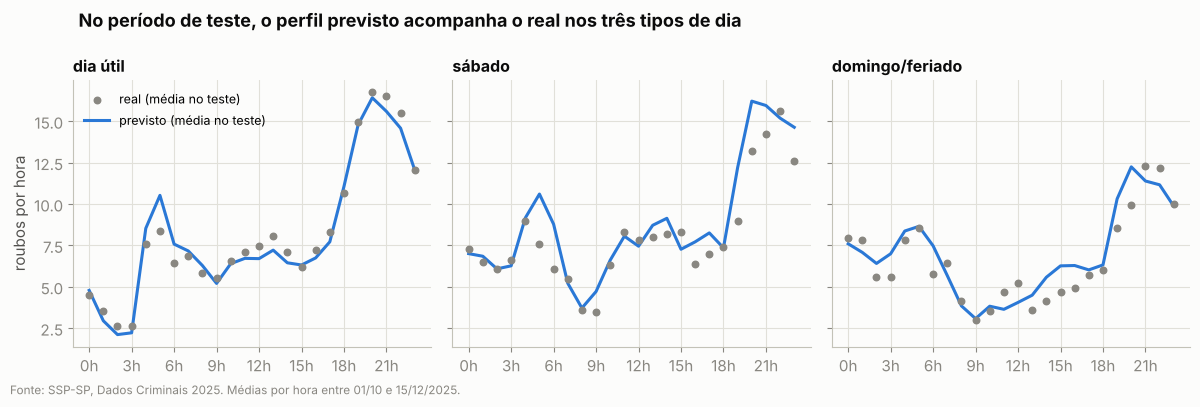

In [22]:
# média por hora no teste: real (pontos) x previsto (linha), por tipo de dia
teste_lin_prev = teste_lin.assign(previsto=previsto_teste)
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.9), sharey=True)
for ax, tipo in zip(eixos, ["dia útil", "sábado", "domingo/feriado"]):
    grupo = (teste_lin_prev[teste_lin_prev["tipo_dia"] == tipo]
             .groupby("hora")[["roubos", "previsto"]].mean())
    ax.scatter(grupo.index, grupo["roubos"], color=TINTA_SUAVE, s=22,
               label="real (média no teste)", zorder=3)
    ax.plot(grupo.index, grupo["previsto"], color=AZUL, linewidth=2.2,
            label="previsto (média no teste)")
    ax.set_title(tipo, fontsize=11.5)
    ax.set_xticks(range(0, 24, 3), [f"{h}h" for h in range(0, 24, 3)])
eixos[0].set_ylabel("roubos por hora")
eixos[0].legend(loc="upper left", fontsize=9)
fig.suptitle("No período de teste, o perfil previsto acompanha o real nos três "
             "tipos de dia", x=0.06, ha="left", fontweight="bold", color=TINTA,
             fontsize=13)
fig.tight_layout()
fonte(fig, "Fonte: SSP-SP, Dados Criminais 2025. Médias por hora entre 01/10 e "
           "15/12/2025.")
salvar(fig, "05_linear_perfil_previsto_por_hora.png")
plt.show()

**Interpretação da regressão linear**

* **Bem melhor que a referência.** Se prevíssemos sempre a média, o erro médio seria de 4,2 roubos por hora e o R² ficaria perto de zero. A regressão erra 2,84 roubos por hora em média (MAE) e explica 48% da variação de uma hora para outra (R² = 0,48).
* **Sem sobreajuste.** O R² no teste (0,483) é praticamente igual ao do treino (0,494), então o modelo aprendeu um padrão que se repete em meses que ele não viu.
* **R² de 0,48 é bom para esse tipo de dado.** Contagens pequenas oscilam por acaso: mesmo que a gente soubesse a média exata de uma hora, o número observado continuaria variando em volta dela. Descontado esse acaso, o máximo que qualquer modelo alcançaria é uns **0,71**, e o nosso chega a cerca de dois terços disso. O RMSE (3,75) ser maior que o MAE (2,84) indica que os maiores erros estão nos picos ao acaso, como os de sexta e sábado no gráfico da semana.
* **Coeficientes:**
  * `escuro` = **+1,72**: na mesma hora e no mesmo tipo de dia, uma hora toda escura tem cerca de 1,7 roubo a mais. Às 18h isso dá **15% a mais**. Então a escuridão pesa no risco, e não só o horário do relógio.
  * `dias_desde_inicio` = **−0,0049 por dia**, ou cerca de 0,15 roubo por hora a menos a cada 30 dias, que é a queda que aparece no gráfico de 2025.
  * `hora_tipo` descreve o perfil do dia. O pico fica entre **19h e 22h** (uns 17 roubos por hora nos dias úteis) e há um segundo pico às **5h**, de quem sai cedo para trabalhar.

## 6. Regressão logística: o problema ainda estará lá depois de 15 dias?

**Modelo:** a regressão logística estima a **probabilidade** de `persiste_15d = 1` a partir do serviço pedido, da subprefeitura e do dia da semana (todos viram colunas 0/1). As referências (`drop`) são o **tapa-buraco**, a subprefeitura da **Sé** e a **segunda-feira**, e cada coeficiente é comparado com elas.

**De probabilidade para "sim ou não".** O modelo diz "persiste" quando a probabilidade passa de um **limiar**. O padrão é 50%, mas para o app é pior errar para menos: se o alerta some do mapa e a calçada quebrada continua lá, a pessoa fica sem aviso. Por isso escolhemos o limiar com o melhor **F1** (equilíbrio entre precisão e recall) numa **validação dentro do treino**: o modelo aprende com janeiro a julho e testamos os limiares em agosto e setembro. O teste (outubro a dezembro) não participa dessa escolha.

**Métricas no teste** (classe positiva = "ainda sem solução depois de 15 dias"):

* **matriz de confusão**: os acertos e os erros de cada tipo;
* **precisão**: dos pedidos que o modelo marcou como "persiste", quantos persistiram de fato;
* **recall**: dos pedidos que persistiram, quantos o modelo encontrou;
* **F1**: média harmônica entre precisão e recall.

In [23]:
def novo_modelo_logistico():
    # one-hot das três variáveis (referências: tapa-buraco, Sé e segunda-feira)
    # e depois a regressão logística
    codificador = OneHotEncoder(drop=["Tapa-buraco", "SE", "seg"],
                                handle_unknown="ignore")
    return Pipeline([
        ("preparo", ColumnTransformer([("categorias", codificador, X_LOGISTICA)])),
        ("regressao", LogisticRegression(max_iter=2000)),
    ])


# validação dentro do treino: aprende com jan a jul e testa os limiares em ago e set
CORTE_VALIDACAO = pd.Timestamp("2025-08-01")
sub_treino = treino_log[treino_log["abertura"] < CORTE_VALIDACAO]
validacao = treino_log[treino_log["abertura"] >= CORTE_VALIDACAO]
modelo_val = novo_modelo_logistico().fit(sub_treino[X_LOGISTICA],
                                         sub_treino["persiste_15d"])
prob_val = modelo_val.predict_proba(validacao[X_LOGISTICA])[:, 1]  # P(persiste)
y_val = validacao["persiste_15d"]

# precisão, recall e F1 para cada limiar de 0,20 a 0,70
limiares = np.round(np.arange(0.20, 0.71, 0.05), 2)
curva = pd.DataFrame({
    "precisão": [precision_score(y_val, (prob_val >= l).astype(int), zero_division=0)
                 for l in limiares],
    "recall": [recall_score(y_val, (prob_val >= l).astype(int)) for l in limiares],
    "F1": [f1_score(y_val, (prob_val >= l).astype(int), zero_division=0)
           for l in limiares],
}, index=limiares)
LIMIAR = float(curva["F1"].idxmax())          # o limiar com maior F1 na validação
print(f"limiar escolhido na validação (ago a set): {num(LIMIAR)} "
      f"(F1 de validação = {num(curva['F1'].max(), 3)})")

limiar escolhido na validação (ago a set): 0,45 (F1 de validação = 0,485)


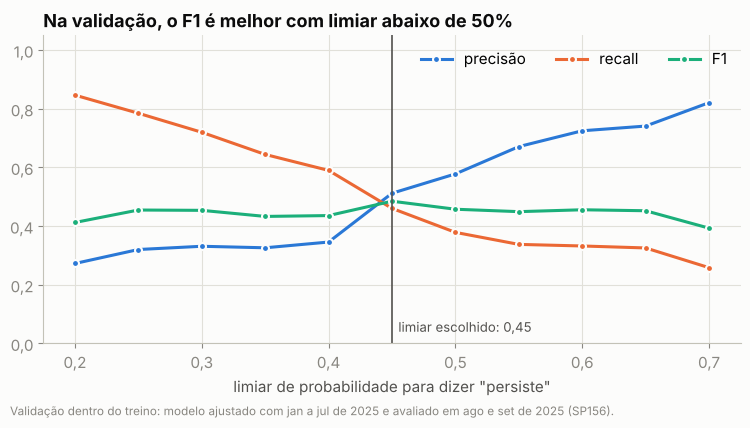

In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
for coluna, cor in [("precisão", AZUL), ("recall", LARANJA), ("F1", VERDE_AGUA)]:
    ax.plot(curva.index, curva[coluna], color=cor, linewidth=2.2, marker="o",
            markersize=5, markeredgecolor=FUNDO, markeredgewidth=1.5, label=coluna)
ax.axvline(LIMIAR, color=TINTA_2, linewidth=1.2)
ax.text(LIMIAR + 0.005, 0.04, f"limiar escolhido: {num(LIMIAR)}", color=TINTA_2,
        fontsize=9.5)
ax.set_ylim(0, 1.05)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v, 1)))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v, 1)))
ax.set_xlabel("limiar de probabilidade para dizer \"persiste\"")
ax.set_title("Na validação, o F1 é melhor com limiar abaixo de 50%")
ax.legend(loc="upper right", ncols=3)
fonte(fig, "Validação dentro do treino: modelo ajustado com jan a jul de 2025 e "
           "avaliado em ago e set de 2025 (SP156).")
salvar(fig, "06_logistica_escolha_do_limiar.png")
plt.show()

In [25]:
# modelo final: aprende com todo o treino (jan a set) e é avaliado no teste (out a dez)
modelo_logistico = novo_modelo_logistico().fit(treino_log[X_LOGISTICA],
                                               treino_log["persiste_15d"])
prob_teste = modelo_logistico.predict_proba(teste_log[X_LOGISTICA])[:, 1]
y_teste = teste_log["persiste_15d"]
previsto_logistica = (prob_teste >= LIMIAR).astype(int)   # aplica o limiar escolhido


def metricas_classificacao(previsto, prob=None):
    auc = roc_auc_score(y_teste, prob) if prob is not None else np.nan
    return {"acurácia": accuracy_score(y_teste, previsto),
            "precisão": precision_score(y_teste, previsto, zero_division=0),
            "recall": recall_score(y_teste, previsto),
            "F1": f1_score(y_teste, previsto, zero_division=0), "AUC": auc}


sempre_0 = np.zeros(len(y_teste), dtype=int)       # referência: tudo "resolvido"
sempre_1 = np.ones(len(y_teste), dtype=int)        # referência: tudo "persiste"
metricas_log = pd.DataFrame({
    "referência: sempre 'resolvido' (0)": metricas_classificacao(sempre_0),
    "referência: sempre 'persiste' (1)": metricas_classificacao(sempre_1),
    "regressão logística, limiar 0,50":
        metricas_classificacao((prob_teste >= 0.5).astype(int), prob_teste),
    f"regressão logística, limiar {num(LIMIAR)}":
        metricas_classificacao(previsto_logistica, prob_teste),
}).T
print(f"teste: {len(y_teste):,} pedidos, {pct(y_teste.mean())} persistiram")
metricas_log.round(3)

teste: 36,404 pedidos, 27,3% persistiram


,acurácia,precisão,recall,F1,AUC
referência: sempre 'resolvido' (0),0.727,0.000,0.000,0.000,NaN
referência: sempre 'persiste' (1),0.273,0.273,1.000,0.429,NaN
"regressão logística, limiar 0,50",0.798,0.765,0.377,0.505,0.722
"regressão logística, limiar 0,45",0.786,0.660,0.446,0.532,0.722


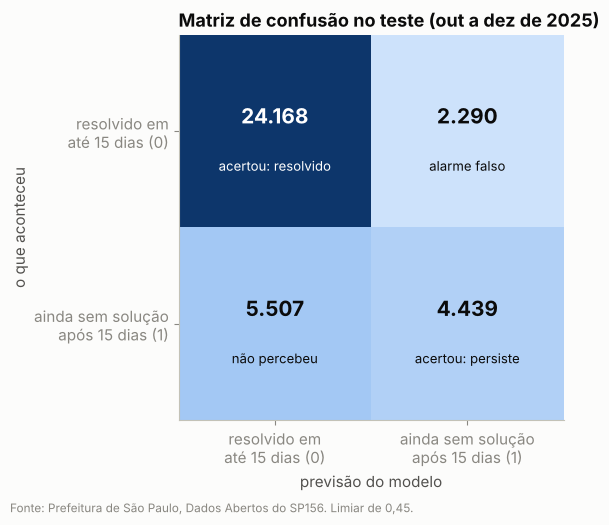

In [26]:
# matriz de confusão: linhas = o que aconteceu, colunas = o que o modelo previu
matriz = confusion_matrix(y_teste, previsto_logistica, labels=[0, 1])
legendas = [["acertou: resolvido", "alarme falso"],
            ["não percebeu", "acertou: persiste"]]

fig, ax = plt.subplots(figsize=(6.4, 5))
ax.imshow(matriz, cmap=AZUIS)
for i in range(2):
    for j in range(2):
        cor = "white" if matriz[i, j] > matriz.max() * 0.45 else TINTA
        ax.text(j, i - 0.08, f"{matriz[i, j]:,}".replace(",", "."), ha="center",
                va="center", color=cor, fontsize=15, fontweight="bold")
        ax.text(j, i + 0.18, legendas[i][j], ha="center", va="center", color=cor,
                fontsize=9.5)
rotulos = ["resolvido em\naté 15 dias (0)", "ainda sem solução\napós 15 dias (1)"]
ax.set_xticks([0, 1], rotulos)
ax.set_yticks([0, 1], rotulos)
ax.set_xlabel("previsão do modelo")
ax.set_ylabel("o que aconteceu")
ax.grid(False)
ax.set_title("Matriz de confusão no teste (out a dez de 2025)")
fonte(fig, f"Fonte: Prefeitura de São Paulo, Dados Abertos do SP156. "
           f"Limiar de {num(LIMIAR)}.")
salvar(fig, "07_logistica_matriz_de_confusao.png")
plt.show()

In [27]:
# em quais categorias estão os casos que persistiram e o modelo não percebeu
nao_percebeu = teste_log[(y_teste == 1) & (previsto_logistica == 0)]
print(f"{len(nao_percebeu):,} casos persistiram e o modelo não percebeu:")
(nao_percebeu["categoria_app"].value_counts(normalize=True).map(pct)
                              .to_frame("% dos casos não percebidos"))

5,507 casos persistiram e o modelo não percebeu:


,% dos casos não percebidos
categoria_app,
Buraco,"73,9%"
Alagamento,"21,2%"
Calçada quebrada,"4,0%"
Falta de rampa,"0,5%"
Degrau (escadaria ou viela),"0,5%"


In [28]:
# razão de chances = exp(coeficiente). Acima de 1 o pedido tem mais chance de
# persistir que a referência; abaixo de 1, menos chance
nomes = modelo_logistico.named_steps["preparo"].get_feature_names_out()
razao = pd.Series(np.exp(modelo_logistico.named_steps["regressao"].coef_[0]),
                  index=nomes)
servicos = (razao[razao.index.str.startswith("categorias__servico_")]
            .rename(lambda n: n.replace("categorias__servico_", "")))
subprefeituras = (razao[razao.index.str.startswith("categorias__subprefeitura_")]
                  .rename(lambda n: n.replace("categorias__subprefeitura_", "")))

print("Razão de chances de persistir depois de 15 dias, contra o tapa-buraco (= 1):")
display(servicos.sort_values(ascending=False).round(2).to_frame("razão de chances"))
print("Subprefeituras contra a Sé (= 1): acima de 1, o problema tende a demorar mais")
lentas = subprefeituras.sort_values(ascending=False).head(5)
rapidas = subprefeituras.sort_values().head(5)
pd.DataFrame({"mais lentas": lentas.index,
              "razão (lentas)": lentas.round(2).to_numpy(),
              "mais rápidas": rapidas.index,
              "razão (rápidas)": rapidas.round(2).to_numpy()})

Razão de chances de persistir depois de 15 dias, contra o tapa-buraco (= 1):


,razão de chances
Obstáculo na calçada,48.87
Calçada particular danificada,47.73
Microdrenagem,12.68
Bueiro e boca de lobo,4.37
Reforma de galeria pluvial,3.74
Viela ou escadaria,3.73
Calçada pública: manutenção,3.08
Rebaixamento de guia,1.31
Limpeza de bueiro,0.75
Tapa-buraco em corredor de ônibus,0.45


Subprefeituras contra a Sé (= 1): acima de 1, o problema tende a demorar mais


,mais lentas,razão (lentas),mais rápidas,razão (rápidas)
0,LAPA,1.31,JABAQUARA,0.13
1,ITAIM PAULISTA,1.28,VILA PRUDENTE,0.20
2,PIRITUBA-JARAGUA,1.18,VILA MARIA-VILA GUILHERME,0.22
3,PINHEIROS,1.06,JACANA-TREMEMBE,0.24
4,SAO MIGUEL,0.85,SANTANA-TUCURUVI,0.25


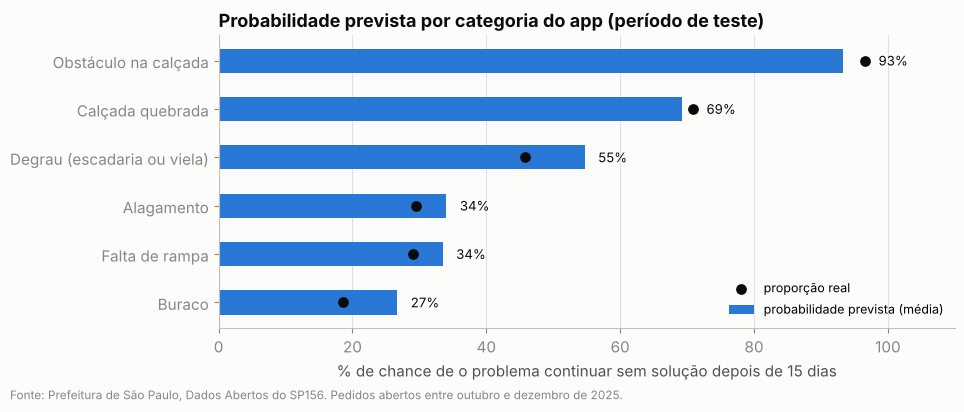

,previsto,real,pedidos
categoria_app,,,
Buraco,"26,7%","18,6%",23045
Falta de rampa,"33,5%","29,1%",141
Alagamento,"34,1%","29,5%",9552
Degrau (escadaria ou viela),"54,7%","45,7%",385
Calçada quebrada,"69,2%","70,9%",2103
Obstáculo na calçada,"93,4%","96,6%",1178


In [29]:
# probabilidade prevista (média) e proporção real de persistência, por categoria do app
por_categoria = (teste_log.assign(prob=prob_teste)
                 .groupby("categoria_app")
                 .agg(previsto=("prob", "mean"), real=("persiste_15d", "mean"),
                      pedidos=("prob", "size"))
                 .sort_values("previsto"))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
y = np.arange(len(por_categoria))
ax.barh(y, por_categoria["previsto"] * 100, height=0.5, color=AZUL,
        label="probabilidade prevista (média)")
ax.scatter(por_categoria["real"] * 100, y, color=TINTA, s=45, zorder=3,
           label="proporção real")
for i, valor in enumerate(por_categoria["previsto"]):
    x_rotulo = max(valor, por_categoria["real"].iloc[i]) * 100 + 2
    ax.text(x_rotulo, i, pct(valor, 0), va="center", color=TINTA, fontsize=9.5)
ax.set_yticks(y, por_categoria.index)
ax.set_xlim(0, 110)
ax.set_xticks(range(0, 101, 20))
ax.grid(axis="y", visible=False)
ax.set_xlabel("% de chance de o problema continuar sem solução depois de 15 dias")
ax.set_title("Probabilidade prevista por categoria do app (período de teste)")
ax.legend(loc="lower right", fontsize=9)
fonte(fig, "Fonte: Prefeitura de São Paulo, Dados Abertos do SP156. Pedidos abertos "
           "entre outubro e dezembro de 2025.")
salvar(fig, "08_logistica_probabilidade_por_categoria.png")
plt.show()
por_categoria.assign(previsto=por_categoria["previsto"].map(pct),
                     real=por_categoria["real"].map(pct))

**Interpretação da regressão logística**

* **Matriz de confusão (limiar 0,45).** Dos 36.404 pedidos do teste, o modelo acertou 28.607 (**acurácia de 78,6%**). Ele marcou 6.729 como "persiste": **4.439 persistiram de fato (precisão de 66%)** e 2.290 foram alarmes falsos. Dos 9.946 que persistiram, encontrou 4.439 (**recall de 45%**). Entre os 5.507 que ele não percebeu, **95% são buracos e bueiros**, serviços que costumam ser resolvidos rápido mas às vezes não são. Com só três variáveis o modelo não tem como saber qual buraco vai demorar.
* **F1 = 0,53**, contra 0,43 de marcar tudo como "persiste" e 0 de marcar tudo como "resolvido". Baixar o limiar de 0,50 para 0,45 custou um pouco de precisão (de 0,77 para 0,66) e rendeu mais recall (de 0,38 para 0,45). Para o app vale a troca: deixar um alerta no mapa um pouco além da conta é menos grave do que apagá-lo com o problema ainda lá.
* **Razões de chances.** Comparado com um buraco, um pedido de **obstáculo na calçada** tem cerca de **49 vezes** mais chance de continuar sem solução depois de 15 dias, e um de **calçada particular danificada**, cerca de **48 vezes**. Entre as subprefeituras, Lapa e Itaim Paulista são as mais lentas, e Jabaquara e Vila Prudente as mais rápidas.
* **Probabilidades por categoria.** O modelo acerta a ordem (obstáculo 93%, calçada quebrada 69%, degrau 55%, buraco 27%) e fica perto da proporção real nas categorias de acessibilidade. Já a persistência dos buracos ele **superestima** (27% previsto contra 19% real), porque aprendeu com o primeiro trimestre, época de chuvas em que os buracos demoravam mais para ser tapados. É uma mudança de padrão ao longo do tempo (*drift*) e uma limitação do modelo.

## 7. Recomendações de ações

As duas tabelas abaixo transformam as previsões em regras que o Caminho Livre (e a Prefeitura) poderiam adotar.

In [30]:
# índice de risco por hora = roubos previstos na hora / média prevista de todas as horas
# (1,0 é uma hora média). Calculado com as previsões do período de teste
perfil_previsto = teste_lin_prev.pivot_table(index="hora", columns="tipo_dia",
                                             values="previsto", aggfunc="mean")
indice_risco = perfil_previsto / teste_lin_prev["previsto"].mean()
indice_risco = indice_risco[["dia útil", "sábado", "domingo/feriado"]]
indice_risco.index = [f"{h}h" for h in indice_risco.index]
print("Índice de risco de roubo previsto por hora (1,0 = hora média):")
indice_risco.round(2)

Índice de risco de roubo previsto por hora (1,0 = hora média):


tipo_dia,dia útil,sábado,domingo/feriado
0h,0.59,0.87,0.94
1h,0.37,0.85,0.88
2h,0.26,0.76,0.80
3h,0.28,0.78,0.87
4h,1.06,1.14,1.04
5h,1.31,1.32,1.07
6h,0.94,1.09,0.93
7h,0.89,0.65,0.71
8h,0.78,0.46,0.48
9h,0.65,0.59,0.38


In [31]:
# validade sugerida para alerta sem confirmação: se a probabilidade prevista de o
# problema persistir passa de 50%, o alerta fica 90 dias (com confirmação a cada 15)
def validade_sugerida(prob):
    if prob >= 0.5:
        return "90 dias, com pedido de confirmação a cada 15"
    return "15 dias (como hoje)"


validade = (por_categoria[["previsto", "real"]]
            .sort_values("previsto", ascending=False).copy())
validade["validade sugerida do alerta"] = validade["previsto"].map(validade_sugerida)
validade.assign(previsto=validade["previsto"].map(pct),
                real=validade["real"].map(pct)).rename(columns={
    "previsto": "prob. prevista de persistir", "real": "proporção real no teste"})

,prob. prevista de persistir,proporção real no teste,validade sugerida do alerta
categoria_app,,,
Obstáculo na calçada,"93,4%","96,6%","90 dias, com pedido de confirmação a cada 15"
Calçada quebrada,"69,2%","70,9%","90 dias, com pedido de confirmação a cada 15"
Degrau (escadaria ou viela),"54,7%","45,7%","90 dias, com pedido de confirmação a cada 15"
Alagamento,"34,1%","29,5%",15 dias (como hoje)
Falta de rampa,"33,5%","29,1%",15 dias (como hoje)
Buraco,"26,7%","18,6%",15 dias (como hoje)


### Ações recomendadas

| # | Ação | Previsão que fundamenta | O que muda para o cidadão | Limitação |
|---|---|---|---|---|
| 1 | **Peso de risco por hora nas rotas:** multiplicar o peso dos alertas de assalto pelo índice previsto da hora (tabela acima), no lugar de um peso único para "noite" | Regressão linear: o risco previsto vai de **0,26** (2h, dia útil) a **2,04** (20h, dia útil) vezes a média | Quem sai da faculdade às 23h recebe rotas que fogem dos alertas de assalto nos horários de maior risco, e de madrugada, quando o risco cai, as rotas não ficam compridas à toa | O modelo vale para a cidade inteira, sem separar bairros, e conta só roubos **registrados** |
| 2 | **"Noite" pelo anoitecer real:** trocar a janela fixa das 19h às 6h pelo intervalo entre o anoitecer e o amanhecer de cada dia (um cálculo simples, que só precisa da data) | Coeficiente `escuro` = **+1,7 roubo por hora** (+15% às 18h) na mesma hora do relógio | No inverno a proteção começa por volta das 17h50 e não às 19h; no verão, as 18h ainda claras não são penalizadas | Efeito médio e observacional: a rotina das pessoas também muda entre verão e inverno |
| 3 | **Validade do alerta por categoria (RF14):** 90 dias para obstáculo, calçada quebrada e degrau, com pedido de confirmação a cada 15 dias; 15 dias para buraco, alagamento e falta de rampa | Regressão logística: probabilidade de persistir de **93%** (obstáculo), **69%** (calçada quebrada) e **55%** (degrau), contra 27% a 34% nas outras | Uma idosa que usa andador não perde, depois de 15 dias, o aviso da calçada quebrada no caminho do posto de saúde: em 7 de cada 10 casos o problema continua lá | "Finalizada" no SP156 quer dizer que o protocolo acabou, não que o conserto foi feito; e um pedido ao SP156 não é igual a um alerta do app |
| 4 | **Lembrete de confirmação no 15º dia** para alertas com alta chance de persistir: pedir a quem passa pelo local que confirme se o problema continua | Recall de 45%: o modelo não acha todos os casos que persistem, e a confirmação da comunidade completa a previsão | O mapa continua confiável sem depender só do modelo | Precisa de usuários ativos em cada região |
| 5 | **Relatório para a Prefeitura** (subprefeituras e SP156): mandar, por subprefeitura, os alertas de acessibilidade com maior chance de continuar sem solução | Razões de chances por serviço (obstáculo com cerca de 49 vezes a chance do buraco) e por subprefeitura (Lapa e Itaim Paulista mais lentas) | Barreiras que travam a passagem de cadeirantes e idosos passam a ter prioridade na zeladoria | Reclamação também reflete quem reclama mais; regiões com poucos usuários aparecem menos |

### Limitações dos modelos

* **Regressão linear:** trata a contagem de roubos como número contínuo (uma regressão de Poisson seria mais adequada para contagens); vale para a cidade toda, sem separar bairros; usa só roubos **registrados** e com hora exata (90% deles); a tendência de queda não deve ser esticada por muitos meses.
* **Regressão logística:** usa só três variáveis e erra mais nos buracos, cujo prazo muda com as chuvas (*drift*); "Finalizada" é o fim do protocolo, não garantia de conserto; o limiar de 0,45 é uma escolha de equilíbrio e pode mudar conforme o custo de cada tipo de erro.
* **Gerais:** só um ano (2025) e uma cidade; os dados dependem de a vítima registrar o BO ou de o cidadão ligar para o 156, então existe subnotificação.

### Impactos esperados

* **Segurança:** rotas que evitam alertas de assalto nos horários em que o risco previsto é de 1,5 a 2 vezes a média, considerando que o escuro, e não só o relógio, aumenta o risco.
* **Acessibilidade:** alertas de calçada e de obstáculo que ficam no mapa enquanto o problema provavelmente continua, para que pessoas com mobilidade reduzida não descubram a barreira só no meio do caminho.
* **Cidade:** dados para decidir onde e quando priorizar conserto, iluminação e policiamento.
* **ODS:** meta **11.7** (espaços públicos seguros, inclusivos e acessíveis, principalmente para mulheres, idosos e pessoas com deficiência) e **ODS 10** (redução das desigualdades).

## 8. Conclusão

* **P1.** Uma regressão linear simples consegue prever o ritmo dos roubos a pedestres ao longo do dia (R² de 0,48 no teste, cerca de dois terços do máximo possível para contagens desse tamanho). O risco quase dobra entre 19h e 22h e **aumenta quando está escuro**, mesmo comparando a mesma hora do relógio.
* **P2.** A regressão logística separa os problemas que costumam continuar sem solução (obstáculo e calçada quebrada) dos que são resolvidos rápido (buraco e bueiro), com F1 de 0,53 contra 0,43 da melhor referência.
* **Para o Caminho Livre:** um peso de risco por hora, com a noite definida pelo anoitecer, e validade de 90 dias, com confirmação, para os alertas de acessibilidade. As duas mudanças mexem no ponto central do projeto, que é avisar quem anda a pé sobre o que o GPS não enxerga, **na hora e pelo tempo certos**.

O relatório em PDF que acompanha este notebook traz o problema, as bases, as técnicas, os resultados e as limitações com mais detalhe.